In [4]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langgraph.checkpoint.memory import MemorySaver

In [5]:
load_dotenv()

True

In [6]:
chat_model = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash"
)

chat_model1 = ChatGroq(
    model="llama-3.3-70b-versatile"
)

In [7]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict) :
    message : Annotated[list[BaseMessage], add_messages]

In [8]:
def chat_messages(state : ChatState) :
    messages = state['message']

    response = chat_model1.invoke(messages)

    return {'message' : [response]}

In [9]:
checkPointer = MemorySaver()

graph = StateGraph(ChatState)

graph.add_node('Chat', chat_messages)

graph.add_edge(START, 'Chat')
graph.add_edge('Chat', END)

Chatbot = graph.compile(checkpointer=checkPointer)

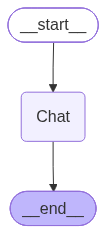

In [ ]:
Chatbot

In [ ]:
initial_state = {
    'message' : [HumanMessage(content='What is the capital of India ?')]
}

Chatbot.invoke(initial_state)['message'][-1].content

'The capital of India is **New Delhi**.'

In [10]:
thread_id = '1'

while True :
    user_msg = input('Type here : ')

    print('User: ', user_msg)

    if user_msg.strip().lower() in ['exit', 'quit', 'bye']:
        break

    config = {'configurable' : {'thread_id' : thread_id}}
    response = Chatbot.invoke({'message' : [HumanMessage(content=user_msg)]}, config=config)

    print('AI: ', response['message'][-1].content)

User:  hy
AI:  How's it going? Is there something I can help you with or would you like to chat?
User:  kaise ho
AI:  Main theek hoon, dhanyavad! (I'm fine, thank you!) Aap kaise hain? (How are you?)
User:  m bhi thik hu
AI:  Bahut achha! (That's great!) Ab aap kya kar rahe hain? Kuch haal-chal share karna chahte hain? (What are you up to? Want to share something?)
User:  kuchh nhi tm btao
AI:  Theek hai! Main aapko kuch interesting baatein bata sakta hoon. Aapko pata hai ki duniya mein sabse bada flower kaun sa hai? (Want me to share something interesting? Did you know what the largest flower in the world is?)

Ya phir main aapko kuch funny jokes suna sakta hoon. Aapko jokes pasand hain? (Or I can share some funny jokes with you. Do you like jokes?)
User:  jokes sunao
AI:  Theek hai! Yeh raha ek chhota sa joke:

Ek Adam ne doctor se kaha, "Doctor sahab, mujhe bhoolne ki bimari hai."
Doctor ne kaha, "Kab se?"
Adam ne kaha, "Kab se... uh... main bhool gaya!"

Aapko yeh joke pasand aaya?